# 07 — Backtesting and Error Analysis (test year 2014)

Stage 08. **The single evaluation on the held-out 2014 test year.** The model configuration is frozen (`results/metrics/xgb_selected_config.json`, chosen on 2013 folds in Stage 07); nothing is changed after seeing these results.

- **Primary:** expanding-window backtest, 12 monthly folds. Before each month XGBoost is refit on all earlier targets with the frozen settings.
- **Secondary:** fixed-origin fit (targets 2010–2013) predicting all of 2014.
- All models are scored on the common eval set (target, pm(t), pm(t−23) observed).

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.stattools import acf

from src.data import load_raw, validate
from src.features import build_dataset
from src import baselines as B, evaluate as E, protocol as P
from src.models import XGBForecaster
from src import plot_style as ps

ps.apply()
df = load_raw(); validate(df)
X, y, split, mask = build_dataset(df)
pm = df['pm25']
cfg = json.loads((E.RESULTS_DIR / 'metrics' / 'xgb_selected_config.json').read_text())
HP = {k: cfg[k] for k in ['max_depth', 'learning_rate', 'n_estimators', 'min_child_weight', 'subsample', 'colsample_bytree', 'reg_lambda']}
make = lambda: XGBForecaster(cfg['formulation'], **HP)
print('frozen config:', cfg['formulation'], HP)

frozen config: delta {'max_depth': 6, 'learning_rate': 0.02, 'n_estimators': 800, 'min_child_weight': 10, 'subsample': 0.85, 'colsample_bytree': 0.6, 'reg_lambda': 5}


## 1. Primary: expanding-window monthly backtest

In [2]:
FOLDS = P.backtest_folds(*P.SPLITS['test'], freq='MS')
xgb_folds, xgb_pred = E.backtest(make, X, y, mask, FOLDS)
tm = mask & (split == 'test')
assert xgb_pred.index.equals(y[tm].index)
preds = {'persistence': B.persistence(pm)[tm], 'seasonal_naive_24h': B.seasonal_naive(pm)[tm], 'xgboost': xgb_pred}
yt = y[tm]
pooled = pd.DataFrame({n: E.metrics(yt, p) for n, p in preds.items()}).T
pooled.round(3)

,n,MAE,RMSE,R2
persistence,8531.0,11.926,22.033,0.944
seasonal_naive_24h,8531.0,67.296,98.754,-0.121
xgboost,8531.0,10.959,19.956,0.954


In [3]:
fold_tab = E.score_by_fold(y, {n: p.reindex(y.index) for n, p in preds.items()}, mask, FOLDS)
wide = fold_tab.pivot(index='fold', columns='model', values=['MAE', 'RMSE'])
wide.index = [f['test_start'].strftime('%b') for f in FOLDS]
for mtr in ['MAE', 'RMSE']:
    wide[(mtr, 'xgb vs pers %')] = 100 * (wide[(mtr, 'xgboost')] - wide[(mtr, 'persistence')]) / wide[(mtr, 'persistence')]
wide.round(2)

MAE                                   RMSE                     \
model persistence seasonal_naive_24h xgboost persistence seasonal_naive_24h   
Jan         17.33             108.20   16.39       33.14             142.43   
Feb         14.42              89.68   13.74       25.32             136.41   
Mar         12.66              81.90   11.21       22.17             109.34   
Apr         12.61              50.72   11.49       29.06              69.80   
May         10.79              42.68   10.32       20.06              56.95   
Jun          9.31              41.74    8.69       15.00              56.38   
Jul          9.70              45.80    8.99       13.90              63.82   
Aug          9.48              38.88    8.73       15.03              51.98   
Sep          9.31              45.89    8.37       14.63              60.05   
Oct         11.39              85.30    9.84       18.08             118.02   
Nov         13.49             101.92   12.13       24.13             137.88   
Dec         12.76              76.07   11.75       24.29             110.41   

                        MAE          RMSE  
model xgboost xgb vs pers % xgb vs pers %  
Jan     31.59         -5.38         -4.68  
Feb     22.99         -4.71         -9.23  
Mar     19.01        -11.45        -14.22  
Apr     26.30         -8.88         -9.50  
May     18.05         -4.30        -10.00  
Jun     13.32         -6.57        -11.21  
Jul     12.72         -7.28         -8.49  
Aug     14.35         -7.93         -4.53  
Sep     13.30        -10.20         -9.11  
Oct     15.18        -13.59        -16.02  
Nov     21.20        -10.02        -12.14  
Dec     21.89         -7.91         -9.89

In [4]:
print('months where XGBoost beats persistence:',
      'MAE', int((wide[('MAE', 'xgb vs pers %')] < 0).sum()), '/ 12;',
      'RMSE', int((wide[('RMSE', 'xgb vs pers %')] < 0).sum()), '/ 12')

months where XGBoost beats persistence: MAE 12 / 12; RMSE 12 / 12


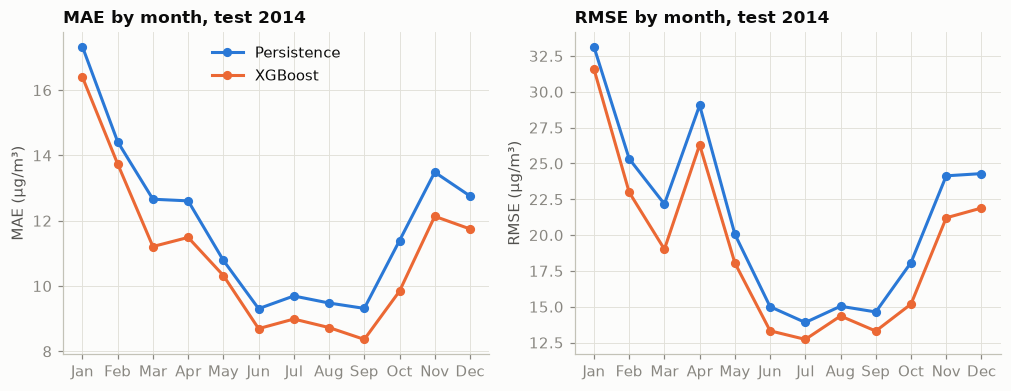

Seasonal-naive is omitted from the plot (monthly MAE 39 – 108 µg/m³); see table above.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(12)
for ax, mtr in zip(axes, ['MAE', 'RMSE']):
    for i, n in enumerate(['persistence', 'xgboost']):
        ax.plot(x, wide[(mtr, n)], marker='o', markersize=5, color=ps.SERIES[i], label=n.capitalize() if n == 'persistence' else 'XGBoost')
    ax.set_xticks(x, wide.index); ax.set(title=f'{mtr} by month, test 2014', ylabel=f'{mtr} (µg/m³)')
axes[0].legend(loc='upper center')
ps.save(fig, 'test_01_monthly'); plt.show()
print('Seasonal-naive is omitted from the plot (monthly MAE', round(wide[('MAE', 'seasonal_naive_24h')].min()), '–',
      round(wide[('MAE', 'seasonal_naive_24h')].max()), 'µg/m³); see table above.')

## 2. Is the difference statistically significant?
Diebold–Mariano test on the 2014 hourly errors (Newey–West variance with 24 lags). A negative statistic means XGBoost has lower loss. A simulation check of this implementation gave about 8% rejections at the nominal 5% level under autocorrelated errors, so p-values are approximate and only very small values are treated as decisive.

In [6]:
e_x, e_p, e_s = xgb_pred - yt, preds['persistence'] - yt, preds['seasonal_naive_24h'] - yt
dm = []
for name, other in [('xgboost vs persistence', e_p), ('xgboost vs seasonal-naive', e_s), ('persistence vs seasonal-naive', e_s)]:
    first = e_p if name.startswith('persistence') else e_x
    for loss in ['squared', 'absolute']:
        s, p = E.diebold_mariano(first, other, loss)
        dm.append({'comparison': name, 'loss': loss, 'DM': s, 'p-value': p})
dm = pd.DataFrame(dm)
print(dm.to_string(index=False, formatters={'DM': '{:.2f}'.format, 'p-value': '{:.1e}'.format}))

                   comparison     loss     DM p-value
       xgboost vs persistence  squared  -5.10 3.4e-07
       xgboost vs persistence absolute  -8.64 5.8e-18
    xgboost vs seasonal-naive  squared  -9.74 2.1e-22
    xgboost vs seasonal-naive absolute -20.66 7.2e-95
persistence vs seasonal-naive  squared  -9.67 4.1e-22
persistence vs seasonal-naive absolute -20.38 2.3e-92


## 3. Secondary evaluations

In [7]:
# 3a. fixed-origin: one model trained on targets up to 2013-12-31 23:00
fixed = [{'fold': 1, 'train_end': pd.Timestamp(P.SPLITS['val'][1]), 'test_start': pd.Timestamp(P.SPLITS['test'][0]), 'test_end': pd.Timestamp(P.SPLITS['test'][1])}]
fx_tab, fx_pred = E.backtest(make, X, y, mask, fixed)
sec = pd.DataFrame({'xgboost, monthly refit (primary)': E.metrics(yt, xgb_pred),
                    'xgboost, fixed origin (2010–13)': E.metrics(yt, fx_pred)}).T
# 3b. XGBoost on every test hour where it can predict (target and pm(t) observed), not only the common set
wide_rows = (split == 'test') & y.notna() & X['pm_lag0'].notna()
allp = pd.concat([E.backtest(make, X, y, wide_rows, [f])[1] for f in FOLDS])
sec.loc['xgboost, monthly refit, all hours with target and pm(t)'] = E.metrics(y[wide_rows], allp)
sec.loc['persistence, same wider set'] = E.metrics(y[wide_rows], pm[wide_rows])
sec.round(3)

,n,MAE,RMSE,R2
"xgboost, monthly refit (primary)",8531.0,10.959,19.956,0.954
"xgboost, fixed origin (2010–13)",8531.0,10.975,19.972,0.954
"xgboost, monthly refit, all hours with target and pm(t)",8626.0,10.957,19.986,0.954
"persistence, same wider set",8626.0,11.925,22.061,0.944


## 4. Error analysis (primary backtest predictions)
### 4a. By pollution level

In [8]:
lvl = pd.cut(yt, [0, 35, 75, 150, 250, 1000], labels=['0–35', '35–75', '75–150', '150–250', '>250'], include_lowest=True)
g = lambda e, f: f(e.groupby(lvl, observed=True))
by_lvl = pd.DataFrame({'hours': e_x.groupby(lvl, observed=True).size(),
    'RMSE pers': g(e_p, lambda s: s.apply(lambda v: np.sqrt((v**2).mean()))), 'RMSE xgb': g(e_x, lambda s: s.apply(lambda v: np.sqrt((v**2).mean()))),
    'MAE pers': g(e_p, lambda s: s.apply(lambda v: v.abs().mean())), 'MAE xgb': g(e_x, lambda s: s.apply(lambda v: v.abs().mean())),
    'bias xgb (mean pred − true)': g(e_x, lambda s: s.mean())})
by_lvl['share of xgb sq. error %'] = 100 * (e_x**2).groupby(lvl, observed=True).sum() / (e_x**2).sum()
by_lvl.round(1)

,hours,RMSE pers,RMSE xgb,MAE pers,MAE xgb,bias xgb (mean pred − true),share of xgb sq. error %
pm25_t+1,,,,,,,
0–35,2485,12.1,10.5,5.6,5.5,3.3,8.0
35–75,1937,18.9,15.7,10.6,9.4,3.2,14.0
75–150,2399,20.2,18.1,13.1,11.8,0.2,23.1
150–250,1061,30.5,26.0,18.8,16.8,-4.2,21.1
>250,649,41.6,42.0,24.2,23.9,-12.8,33.8


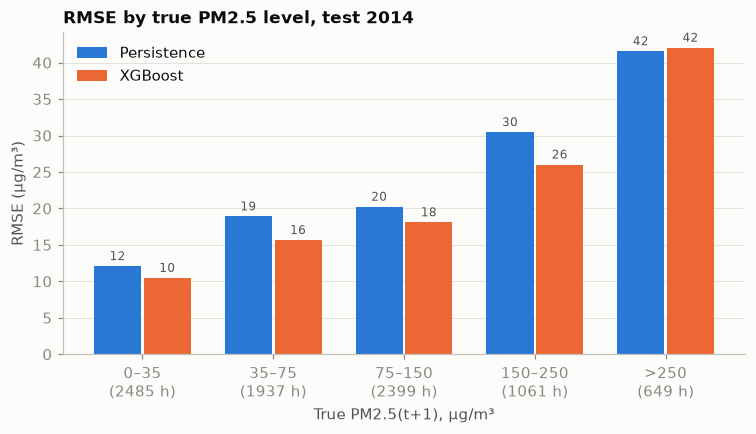

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
xx = np.arange(len(by_lvl)); w = 0.38
for i, (lab, col) in enumerate([('Persistence', 'RMSE pers'), ('XGBoost', 'RMSE xgb')]):
    b = ax.bar(xx + (i - 0.5) * w, by_lvl[col], width=w - 0.02, color=ps.SERIES[i], label=lab)
    ax.bar_label(b, fmt='%.0f', fontsize=8, color=ps.INK_2, padding=2)
ax.set_xticks(xx, [f'{l}\n({n} h)' for l, n in zip(by_lvl.index, by_lvl['hours'])])
ax.set(title='RMSE by true PM2.5 level, test 2014', xlabel='True PM2.5(t+1), µg/m³', ylabel='RMSE (µg/m³)')
ax.grid(axis='x', visible=False); ax.legend(loc='upper left')
ps.save(fig, 'test_02_by_level'); plt.show()

### 4b. Rises, falls and stable hours
Hours are grouped by the true one-hour change Δ = pm(t+1) − pm(t). Persistence's error is exactly −Δ, so it is worst when PM2.5 moves a lot.

In [10]:
delta = yt - pm[tm]
mv = pd.cut(delta, [-1000, -50, -10, 10, 50, 1000], labels=['big fall (≤ −50)', 'fall (−50 to −10]', 'stable (−10 to 10]', 'rise (10 to 50]', 'big rise (> 50)'])
pd.DataFrame({'hours': delta.groupby(mv, observed=True).size(),
              'MAE pers': e_p.abs().groupby(mv, observed=True).mean(), 'MAE xgb': e_x.abs().groupby(mv, observed=True).mean(),
              'bias xgb': e_x.groupby(mv, observed=True).mean()}).round(1)

,hours,MAE pers,MAE xgb,bias xgb
big fall (≤ −50),178,84.7,60.6,59.3
fall (−50 to −10],1343,20.1,16.9,15.0
stable (−10 to 10],5408,4.0,5.0,0.8
rise (10 to 50],1511,20.0,16.9,-16.5
big rise (> 50),91,85.1,84.9,-84.9


### 4c. Stage 03 hypothesis: do sharp drops coincide with a shift to north-westerly wind?
For each test hour, `NW onset` = wind is NW at *t* and has been for ≤ 3 h (known at issuance time).

In [11]:
nw_onset = (X.loc[tm, 'wind_NW'] == 1) & (X.loc[tm, 'wind_dir_hours'] <= 3)
big_fall = delta <= -50   # same definition as the 'big fall' group above
pd.DataFrame({'P(NW onset)': [nw_onset.mean(), nw_onset[big_fall].mean(), nw_onset[~big_fall].mean()],
              'hours': [len(nw_onset), int(big_fall.sum()), int((~big_fall).sum())]},
             index=['all test hours', 'big-fall hours', 'other hours']).round(3)

,P(NW onset),hours
all test hours,0.134,8531
big-fall hours,0.242,178
other hours,0.131,8353


In [12]:
ct = pd.DataFrame({'MAE pers': e_p.abs().groupby(nw_onset).mean(), 'MAE xgb': e_x.abs().groupby(nw_onset).mean(),
                   'hours': e_x.groupby(nw_onset).size()})
ct.index = ['no NW onset', 'NW onset']
ct.round(1)

,MAE pers,MAE xgb,hours
no NW onset,11.8,10.9,7390
NW onset,13.0,11.5,1141


### 4d. Time-of-day pattern and residual autocorrelation

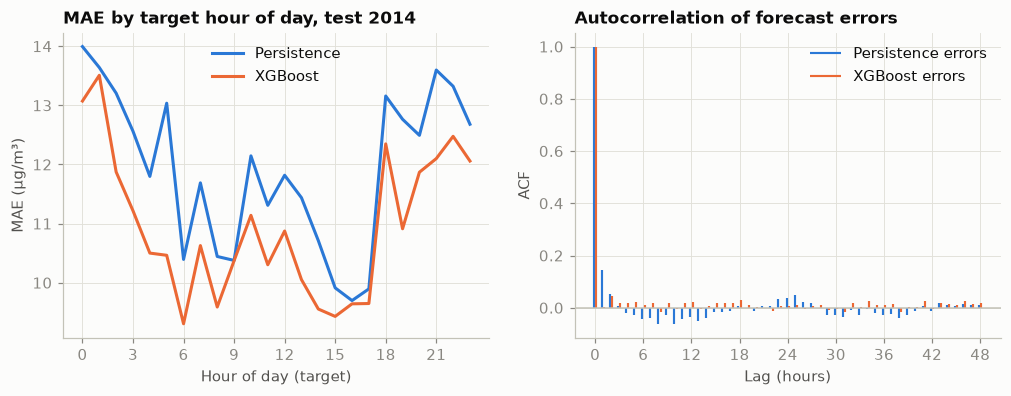

,lag 1,lag 2,lag 3,lag 24
persistence,0.143,0.054,0.007,0.038
xgboost,0.003,0.044,0.020,0.006


In [13]:
hr = (yt.index + pd.Timedelta(hours=1)).hour
hod = pd.DataFrame({'persistence': e_p.abs().groupby(hr).mean(), 'xgboost': e_x.abs().groupby(hr).mean()})
r_acf = acf(e_x.reindex(pd.date_range(yt.index.min(), yt.index.max(), freq='h')), nlags=48, missing='conservative')
p_acf = acf(e_p.reindex(pd.date_range(yt.index.min(), yt.index.max(), freq='h')), nlags=48, missing='conservative')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for i, n in enumerate(hod.columns): a1.plot(hod.index, hod[n], color=ps.SERIES[i], label='Persistence' if i == 0 else 'XGBoost')
a1.set(title='MAE by target hour of day, test 2014', xlabel='Hour of day (target)', ylabel='MAE (µg/m³)', xticks=range(0, 24, 3)); a1.legend()
a2.vlines(np.arange(49) - 0.15, 0, p_acf, color=ps.SERIES[0], linewidth=1.4, label='Persistence errors')
a2.vlines(np.arange(49) + 0.15, 0, r_acf, color=ps.SERIES[1], linewidth=1.4, label='XGBoost errors')
a2.axhline(0, color=ps.AXIS, linewidth=1)
a2.set(title='Autocorrelation of forecast errors', xlabel='Lag (hours)', ylabel='ACF', xticks=range(0, 49, 6)); a2.legend()
ps.save(fig, 'test_03_hour_and_residual_acf'); plt.show()
pd.DataFrame({'persistence': p_acf[[1, 2, 3, 24]], 'xgboost': r_acf[[1, 2, 3, 24]]}, index=['lag 1', 'lag 2', 'lag 3', 'lag 24']).round(3).T

### 4e. Example: largest test-year episode

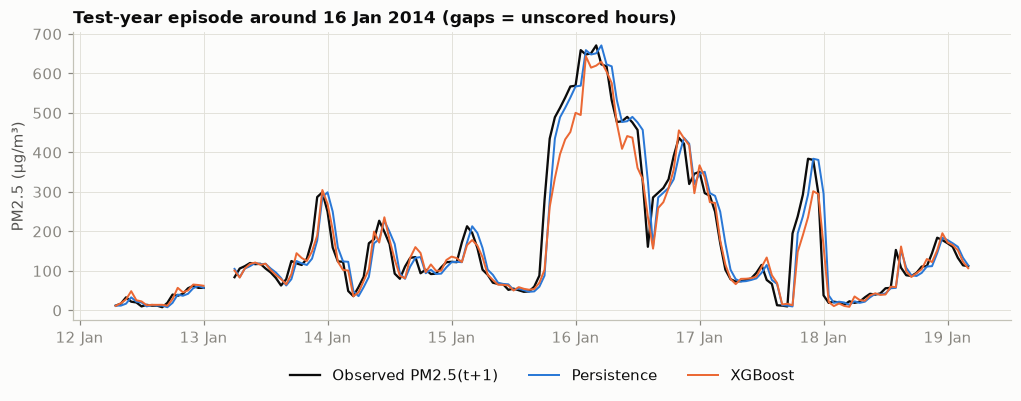

In [14]:
peak = yt.idxmax()
hours = pd.date_range(peak - pd.Timedelta(days=4), peak + pd.Timedelta(days=3), freq='h')   # full grid: unscored hours break the lines
tt = hours + pd.Timedelta(hours=1)
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(tt, yt.reindex(hours), color=ps.INK, linewidth=1.5, label='Observed PM2.5(t+1)')
ax.plot(tt, preds['persistence'].reindex(hours), color=ps.SERIES[0], linewidth=1.3, label='Persistence')
ax.plot(tt, xgb_pred.reindex(hours), color=ps.SERIES[1], linewidth=1.3, label='XGBoost')
ax.set(title=f'Test-year episode around {(peak + pd.Timedelta(hours=1)):%d %b %Y} (gaps = unscored hours)', ylabel='PM2.5 (µg/m³)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b')); ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=3)
ps.save(fig, 'test_04_episode'); plt.show()

## 5. Save

In [15]:
M = E.RESULTS_DIR / 'metrics'
pooled.to_csv(M / 'test_pooled.csv', index_label='model'); fold_tab.to_csv(M / 'test_monthly_folds.csv', index=False)
dm.to_csv(M / 'test_diebold_mariano.csv', index=False); sec.to_csv(M / 'test_secondary.csv', index_label='evaluation')
by_lvl.to_csv(M / 'test_by_level.csv', index_label='true_pm25_band')
pd.DataFrame({'target_time': yt.index + pd.Timedelta(hours=1), 'y_true': yt, **preds, 'xgboost_fixed_origin': fx_pred}) \
  .to_csv(E.RESULTS_DIR / 'predictions' / 'test_2014.csv', index_label='issue_time')
print('saved')

saved


## 6. Findings (test 2014, single evaluation)
1. **XGBoost beats persistence on the test year:** MAE 10.96 vs 11.93 (−8.1%), RMSE 19.96 vs 22.03 (−9.4%), R² 0.954 vs 0.944, on the same 8,531 hours. It is better in **all 12 months** on both MAE and RMSE. Diebold–Mariano: p ≈ 3×10⁻⁷ (squared) and 6×10⁻¹⁸ (absolute), well beyond the test's mild over-rejection.
2. **The gains match validation** (2013: −7.0% MAE, −9.4% RMSE), so the Stage 07 choices generalised. Both models score better on 2014 than on 2013; 2014 appears to be an easier year (persistence RMSE 22.0 vs 24.9).
3. **Monthly refitting adds nothing at this horizon:** a single fit on 2010–2013 scores almost identically (RMSE 19.97 vs 19.96). Scoring XGBoost on the wider set of hours (8,626) does not change the picture.
4. **Seasonal-naive** remains worse than the mean (R² −0.12) and far worse than both other models.
5. **Extremes are not improved:** for true PM2.5 > 250 µg/m³, XGBoost RMSE is 42.0 vs 41.6 for persistence and it under-predicts by 12.8 µg/m³ on average. These hours are 7.6% of the test set but 34% of XGBoost's squared error.
6. **Falls are anticipated, rises are not:** for big falls (Δ ≤ −50) MAE drops from 84.7 to 60.6, but for big rises (Δ > 50) XGBoost is no better than persistence (84.9 vs 85.1). On stable hours XGBoost is slightly worse (MAE 5.0 vs 4.0), the price of predicting small changes that do not happen.
7. **Stage 03 hypothesis supported (descriptively):** a recent onset of north-westerly wind is about 1.8× as common before big-fall hours (24.2%) as before other hours (13.1%). The wind features give XGBoost advance warning of clean-air arrivals but not of pollution build-up.
8. **Residuals:** persistence errors have lag-1 autocorrelation 0.14, XGBoost's 0.003, so XGBoost has absorbed the short-term structure that persistence leaves. No strong daily (lag-24) pattern remains.

**Limitations:** one city/station and one test year; the significance test is approximate; features use only observed weather, so an operational system with weather forecasts might anticipate rises better (not tested).